In [530]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

dl = pd.read_csv(r"C:\Users\Haidar\PROJEK\TUGAS\ANALISIS EKSPLORASI\DATA 1\Balaji Fast Food Sales.csv")

In [531]:
dl

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,received_by,time_of_sale
0,1,07-03-2022,Aalopuri,Fastfood,20,13,260,NaN,Mr.,Night
1,2,8/23/2022,Vadapav,Fastfood,20,15,300,Cash,Mr.,Afternoon
2,3,11/20/2022,Vadapav,Fastfood,20,1,20,Cash,Mr.,Afternoon
3,4,02-03-2023,Sugarcane juice,Beverages,25,6,150,Online,Mr.,Night
4,5,10-02-2022,Sugarcane juice,Beverages,25,8,200,Online,Mr.,Evening
...,...,...,...,...,...,...,...,...,...,...
995,996,3/19/2023,Frankie,Fastfood,50,10,500,NaN,Mrs.,Evening
996,997,9/20/2022,Sandwich,Fastfood,60,7,420,NaN,Mr.,Evening
997,998,1/26/2023,Sandwich,Fastfood,60,13,780,NaN,Mr.,Evening
998,999,8/27/2022,Panipuri,Fastfood,20,5,100,NaN,Mrs.,Afternoon


In [532]:
df=dl.dropna()

In [533]:
df

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,received_by,time_of_sale
1,2,8/23/2022,Vadapav,Fastfood,20,15,300,Cash,Mr.,Afternoon
2,3,11/20/2022,Vadapav,Fastfood,20,1,20,Cash,Mr.,Afternoon
3,4,02-03-2023,Sugarcane juice,Beverages,25,6,150,Online,Mr.,Night
4,5,10-02-2022,Sugarcane juice,Beverages,25,8,200,Online,Mr.,Evening
5,6,11/14/2022,Vadapav,Fastfood,20,10,200,Cash,Mr.,Evening
...,...,...,...,...,...,...,...,...,...,...
991,992,10/21/2022,Sandwich,Fastfood,60,5,300,Cash,Mr.,Morning
992,993,7/17/2022,Frankie,Fastfood,50,3,150,Online,Mrs.,Night
993,994,11-01-2022,Panipuri,Fastfood,20,2,40,Online,Mrs.,Evening
994,995,6/18/2022,Sugarcane juice,Beverages,25,1,25,Online,Mr.,Night


In [534]:
df_category = df.groupby('item_name')['item_type'].value_counts().sort_values(ascending=False)

In [535]:
df_category

item_name        item_type
Cold coffee      Beverages    138
Sugarcane juice  Beverages    136
Panipuri         Fastfood     135
Frankie          Fastfood     127
Vadapav          Fastfood     121
Aalopuri         Fastfood     119
Sandwich         Fastfood     117
Name: count, dtype: int64

In [536]:
df['item_type'].value_counts()

item_type
Fastfood     619
Beverages    274
Name: count, dtype: int64

In [537]:
df['transaction_type'].value_counts()

transaction_type
Cash      476
Online    417
Name: count, dtype: int64

In [538]:
df['time_of_sale'].value_counts()

time_of_sale
Evening      185
Night        182
Afternoon    181
Midnight     177
Morning      168
Name: count, dtype: int64

In [539]:
df['date'] = pd.to_datetime(df['date'], format='mixed').dt.strftime('%Y-%m-%d')
df['date'] = pd.to_datetime(df['date'], format='mixed')
df['month']=df['date'].dt.strftime('%B %Y')
df['day'] = df['date'].dt.day_name()

In [540]:
df=df.drop(columns='received_by') 
df

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,time_of_sale,month,day
1,2,2022-08-23,Vadapav,Fastfood,20,15,300,Cash,Afternoon,August 2022,Tuesday
2,3,2022-11-20,Vadapav,Fastfood,20,1,20,Cash,Afternoon,November 2022,Sunday
3,4,2023-02-03,Sugarcane juice,Beverages,25,6,150,Online,Night,February 2023,Friday
4,5,2022-10-02,Sugarcane juice,Beverages,25,8,200,Online,Evening,October 2022,Sunday
5,6,2022-11-14,Vadapav,Fastfood,20,10,200,Cash,Evening,November 2022,Monday
...,...,...,...,...,...,...,...,...,...,...,...
991,992,2022-10-21,Sandwich,Fastfood,60,5,300,Cash,Morning,October 2022,Friday
992,993,2022-07-17,Frankie,Fastfood,50,3,150,Online,Night,July 2022,Sunday
993,994,2022-11-01,Panipuri,Fastfood,20,2,40,Online,Evening,November 2022,Tuesday
994,995,2022-06-18,Sugarcane juice,Beverages,25,1,25,Online,Night,June 2022,Saturday


In [541]:
df_sale = df.groupby('item_price').agg(total_sale=('item_price','count'),unit_terjual=('quantity','sum'),produk=('item_name','first'))

In [542]:
df_sale

,total_sale,unit_terjual,produk
item_price,,,
20,375,2950,Vadapav
25,136,1121,Sugarcane juice
40,138,1142,Cold coffee
50,127,1053,Frankie
60,117,968,Sandwich


In [543]:
df_order=df[['order_id','date','time_of_sale','day']].copy()

In [544]:
df_order = df_order.sort_values('date')

In [545]:
df_order

,order_id,date,time_of_sale,day
690,691,2022-04-01,Evening,Friday
571,572,2022-04-02,Afternoon,Saturday
622,623,2022-04-02,Midnight,Saturday
393,394,2022-04-03,Morning,Sunday
412,413,2022-04-03,Midnight,Sunday
...,...,...,...,...
431,432,2023-03-27,Afternoon,Monday
774,775,2023-03-27,Night,Monday
547,548,2023-03-29,Afternoon,Wednesday
96,97,2023-03-29,Evening,Wednesday


In [546]:
df_tahun = (
    pd.to_datetime(df['month'], format='mixed').dt.to_period('M')
    .value_counts()
    .sort_index()
    .rename('sales_month')
    .to_frame()
)
df_tahun.index = df_tahun.index.to_timestamp().strftime('%B %Y')

df_tahun.reset_index()
df_tahun

,sales_month
month,
April 2022,58
May 2022,90
June 2022,61
July 2022,74
August 2022,80
September 2022,63
October 2022,89
November 2022,74
December 2022,78


In [547]:
df_plot = df_tahun.reset_index()

In [548]:
df_plot

,month,sales_month
0,April 2022,58
1,May 2022,90
2,June 2022,61
3,July 2022,74
4,August 2022,80
5,September 2022,63
6,October 2022,89
7,November 2022,74
8,December 2022,78
9,January 2023,80


In [549]:
df.groupby('date')['quantity'].sum()

date
2022-04-01     7
2022-04-02    30
2022-04-03    22
2022-04-04    33
2022-04-05     2
              ..
2023-03-25    29
2023-03-26    12
2023-03-27    40
2023-03-29    27
2023-03-30    14
Name: quantity, Length: 339, dtype: int64

In [550]:
df.groupby('date').agg({'quantity': 'sum','time_of_sale':'sum'})

,quantity,time_of_sale
date,,
2022-04-01,7,Evening
2022-04-02,30,AfternoonMidnight
2022-04-03,22,MorningMidnightNight
2022-04-04,33,EveningAfternoonAfternoon
2022-04-05,2,Morning
...,...,...
2023-03-25,29,MidnightAfternoonAfternoon
2023-03-26,12,MorningEveningMidnight
2023-03-27,40,AfternoonMidnightMidnightNight


In [551]:
p=df.groupby('item_name')['quantity'].sum()
p.sort_values(ascending=False)

item_name
Cold coffee        1142
Sugarcane juice    1121
Panipuri           1119
Frankie            1053
Sandwich            968
Aalopuri            928
Vadapav             903
Name: quantity, dtype: int64

In [552]:
df['transaction_type'].value_counts()

transaction_type
Cash      476
Online    417
Name: count, dtype: int64

In [553]:
df.nlargest(10,'quantity')

,order_id,date,item_name,item_type,item_price,quantity,transaction_amount,transaction_type,time_of_sale,month,day
1,2,2022-08-23,Vadapav,Fastfood,20,15,300,Cash,Afternoon,August 2022,Tuesday
20,21,2022-12-21,Cold coffee,Beverages,40,15,600,Cash,Evening,December 2022,Wednesday
50,51,2022-05-16,Frankie,Fastfood,50,15,750,Online,Morning,May 2022,Monday
85,86,2023-03-09,Aalopuri,Fastfood,20,15,300,Cash,Morning,March 2023,Thursday
89,90,2022-10-29,Vadapav,Fastfood,20,15,300,Online,Night,October 2022,Saturday
91,92,2022-05-13,Aalopuri,Fastfood,20,15,300,Cash,Afternoon,May 2022,Friday
135,136,2022-08-24,Aalopuri,Fastfood,20,15,300,Online,Morning,August 2022,Wednesday
137,138,2022-09-01,Sandwich,Fastfood,60,15,900,Online,Night,September 2022,Thursday
186,187,2022-10-11,Aalopuri,Fastfood,20,15,300,Cash,Morning,October 2022,Tuesday
192,193,2023-02-05,Cold coffee,Beverages,40,15,600,Online,Midnight,February 2023,Sunday


In [554]:
l=df.groupby('item_name')['time_of_sale'].value_counts()
l
##nanti buat visualisasi yang nampilin perbandingan waktu di satu item kalo bisa dibuat kaya filter item

item_name        time_of_sale
Aalopuri         Midnight        30
                 Morning         25
                 Afternoon       24
                 Night           23
                 Evening         17
Cold coffee      Night           33
                 Morning         28
                 Evening         27
                 Afternoon       27
                 Midnight        23
Frankie          Night           31
                 Afternoon       28
                 Evening         26
                 Midnight        22
                 Morning         20
Panipuri         Evening         35
                 Morning         26
                 Midnight        26
                 Night           25
                 Afternoon       23
Sandwich         Evening         27
                 Night           26
                 Midnight        24
                 Morning         21
                 Afternoon       19
Sugarcane juice  Afternoon       39
                 Evening         3

In [555]:
plt.figure(figsize=(12,6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

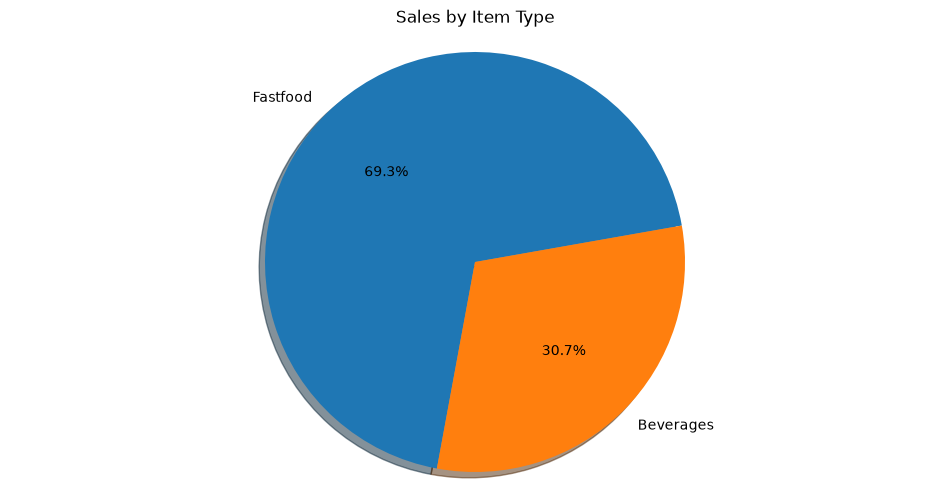

In [556]:
plt.figure(figsize=(12,6))
df['item_type'].value_counts().plot(kind='pie',shadow=True,startangle=10, color='skyblue', autopct='%1.1f%%')
plt.title('Sales by Item Type')
plt.axis('equal')
plt.show()

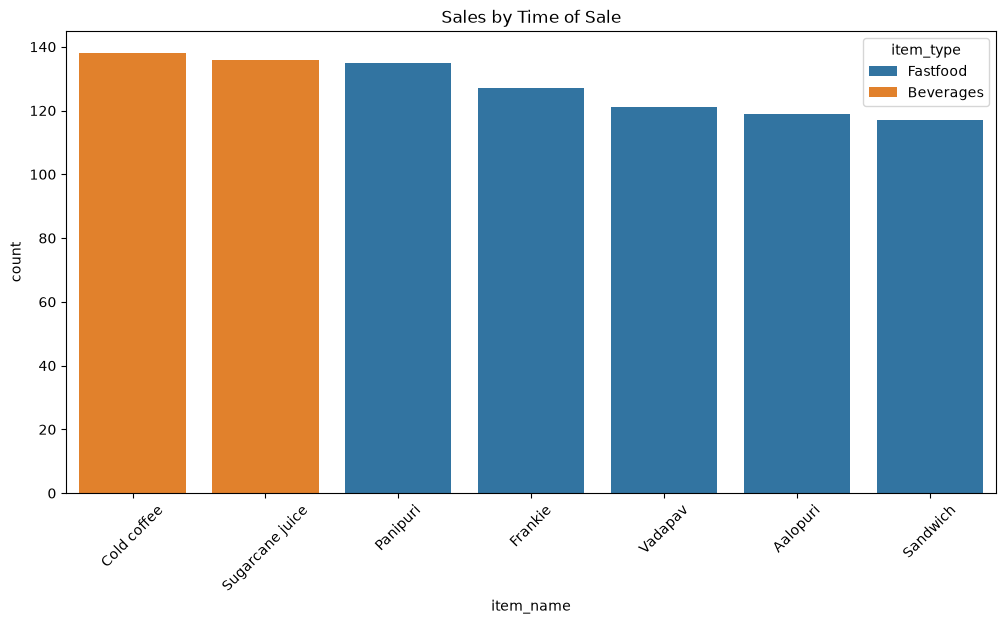

In [557]:
plt.figure(figsize=(12,6))

orders=df['item_name'].value_counts().index
sns.countplot(data=df, x = 'item_name',hue='item_type',order=orders)
plt.xticks(rotation=45)
plt.xlabel=('Item Name')
plt.ylabel=('Count')
plt.title('Sales by Time of Sale')
plt.show()

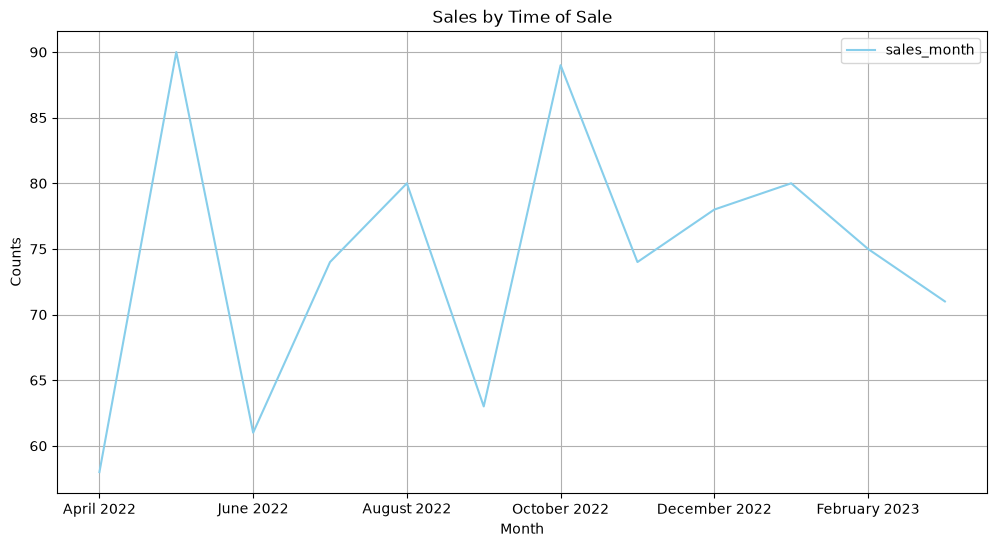

In [558]:
ax = df_plot.plot(kind='line', x='month',figsize=(12, 6), color='skyblue',grid=True)

ax.set_xlabel('Month')
ax.set_ylabel('Counts')
ax.set_title('Sales by Time of Sale')
plt.show()

